# Rice Leaf Disease Classification: CNN from Scratch vs. Transfer Learning (ResNet18)


## 0. Setup

Install the extra libraries, import everything, fix the random seed (reproducibility) and choose the device.

In [ ]:
!pip install -q torchinfo grad-cam

import os, random, time, copy, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from torchinfo import summary

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 1.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
# ----------------------------- Configuration -----------------------------
SEED       = 42
IMG_SIZE   = 224
BATCH_SIZE = 32
EPOCHS     = 10          # epochs per training run
DEBUG      = False       # True -> 1 epoch per run, just to check the code works

ZIP_PATH     = '/content/drive/MyDrive/Colab Notebooks/file_dataset_RiceyLeafDisease.zip'
EXTRACT_PATH = '/content/dataset'
CKPT_DIR     = '/content/checkpoints'     # best weights of every run are saved here

if DEBUG:
    EPOCHS = 1
os.makedirs(CKPT_DIR, exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cpu


## 1. Data Preparation

### 1.1 Load the dataset
The ZIP file is read from Google Drive and extracted once into `/content/dataset`.
The image folder is then located automatically; each sub-folder name is a class label.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

IMG_EXT = ('.png', '.jpg', '.jpeg')

def has_images():
    return any(f.lower().endswith(IMG_EXT) for _, _, fs in os.walk(EXTRACT_PATH) for f in fs)

def unzip(path, dest):
    with zipfile.ZipFile(path, 'r') as z:
        z.extractall(dest)

os.makedirs(EXTRACT_PATH, exist_ok=True)

# Step 1: extract the outer ZIP (skipped if something is already extracted)
if not os.listdir(EXTRACT_PATH):
    print('Extracting outer ZIP (large file, please wait)...')
    unzip(ZIP_PATH, EXTRACT_PATH)

# Step 2: the Mendeley dataset contains ZIPs inside the ZIP (Original.zip, Augmented.zip).
# Extract the nested ZIPs next to themselves; the 'Augmented' copy is skipped (not needed, saves time/disk).
for _ in range(3):                                   # in case of several nesting levels
    if has_images():
        break
    nested = [os.path.join(r, f) for r, _, fs in os.walk(EXTRACT_PATH) for f in fs
              if f.lower().endswith('.zip') and 'augmented' not in (r + f).lower()]
    if not nested:
        break
    for z in nested:
        print('Extracting nested ZIP:', z)
        unzip(z, os.path.dirname(z))
        os.remove(z)                                 # free disk space

print('Images found after extraction:', has_images())

Mounted at /content/drive
Extracting outer ZIP (large file, please wait)...
Extracting nested ZIP: /content/dataset/RiceyLeafDisease An Extensive Image Dataset of Diverse Rice Leaf Diseases from Different Regions of Bangladesh/Original/Original Images.zip
Images found after extraction: True


In [ ]:
# Find the folder that directly contains one sub-folder per class (each class folder holds the images).
# Tolerant search: a folder counts as a "class folder" if it directly contains at least one image;
# the parent with the most class folders wins, and paths containing 'Original' are preferred
# (the dataset also ships an augmented copy that we do not want).
IMG_EXT = ('.png', '.jpg', '.jpeg')

def n_images(path):
    return sum(f.lower().endswith(IMG_EXT) for f in os.listdir(path))

candidates = []
for root, dirs, files in os.walk(EXTRACT_PATH):
    if '__MACOSX' in root:
        continue
    class_dirs = [d for d in dirs if n_images(os.path.join(root, d)) > 0]
    if len(class_dirs) >= 2:
        candidates.append((root, len(class_dirs)))

if not candidates:
    # Help debugging: show what was actually extracted (first 3 levels)
    for root, dirs, files in os.walk(EXTRACT_PATH):
        depth = root[len(EXTRACT_PATH):].count(os.sep)
        if depth <= 3:
            print('  ' * depth + os.path.basename(root) + f'/  ({len(files)} files)')
    raise FileNotFoundError('No class folders with images found under ' + EXTRACT_PATH +
                            '. Delete /content/dataset, re-run the extraction cell and check ZIP_PATH.')

# Prefer 'Original' folders, then the one with the most class folders (shallowest path breaks ties)
candidates.sort(key=lambda t: (not ('Original' in t[0]), -t[1], len(t[0])))
DATA_DIR = candidates[0][0]

classes = sorted(d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d)) and n_images(os.path.join(DATA_DIR, d)) > 0)
class_to_idx = {c: i for i, c in enumerate(classes)}   # single, sorted label mapping used everywhere
NUM_CLASSES = len(classes)

rows = []
for c in classes:
    for f in os.listdir(os.path.join(DATA_DIR, c)):
        if f.lower().endswith(IMG_EXT):
            rows.append((os.path.join(DATA_DIR, c, f), c))
df = pd.DataFrame(rows, columns=['filepath', 'label'])

print('Dataset folder :', DATA_DIR)
print('Classes        :', classes)
print('Total images   :', len(df))

Dataset folder : /content/dataset/RiceyLeafDisease An Extensive Image Dataset of Diverse Rice Leaf Diseases from Different Regions of Bangladesh/Original/Original Images
Classes        : ['Bacterial Leaf Blight', 'Brown Spot', 'Healthy Rice Leaf', 'Leaf Blast', 'Leaf scald', 'Narrow Brown Leaf Spot', 'Rice Hispa', 'Sheath Blight']
Total images   : 1701


### 1.2 Number of images per class and sample images
A table and a bar chart show the class distribution (check for class imbalance), followed by one random example per class.

,Class,Images,Percentage (%)
0,Leaf Blast,305,17.93
1,Sheath Blight,271,15.93
2,Brown Spot,267,15.70
3,Rice Hispa,215,12.64
4,Leaf scald,189,11.11
5,Bacterial Leaf Blight,180,10.58
6,Healthy Rice Leaf,157,9.23
7,Narrow Brown Leaf Spot,117,6.88


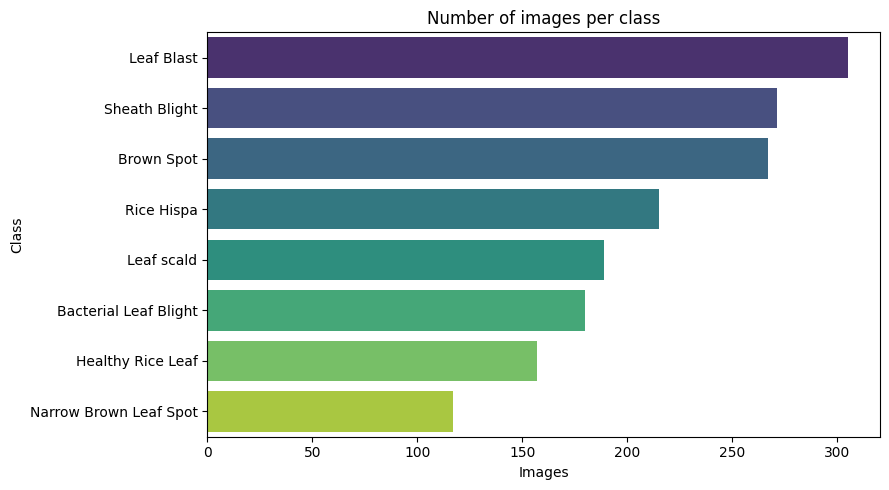

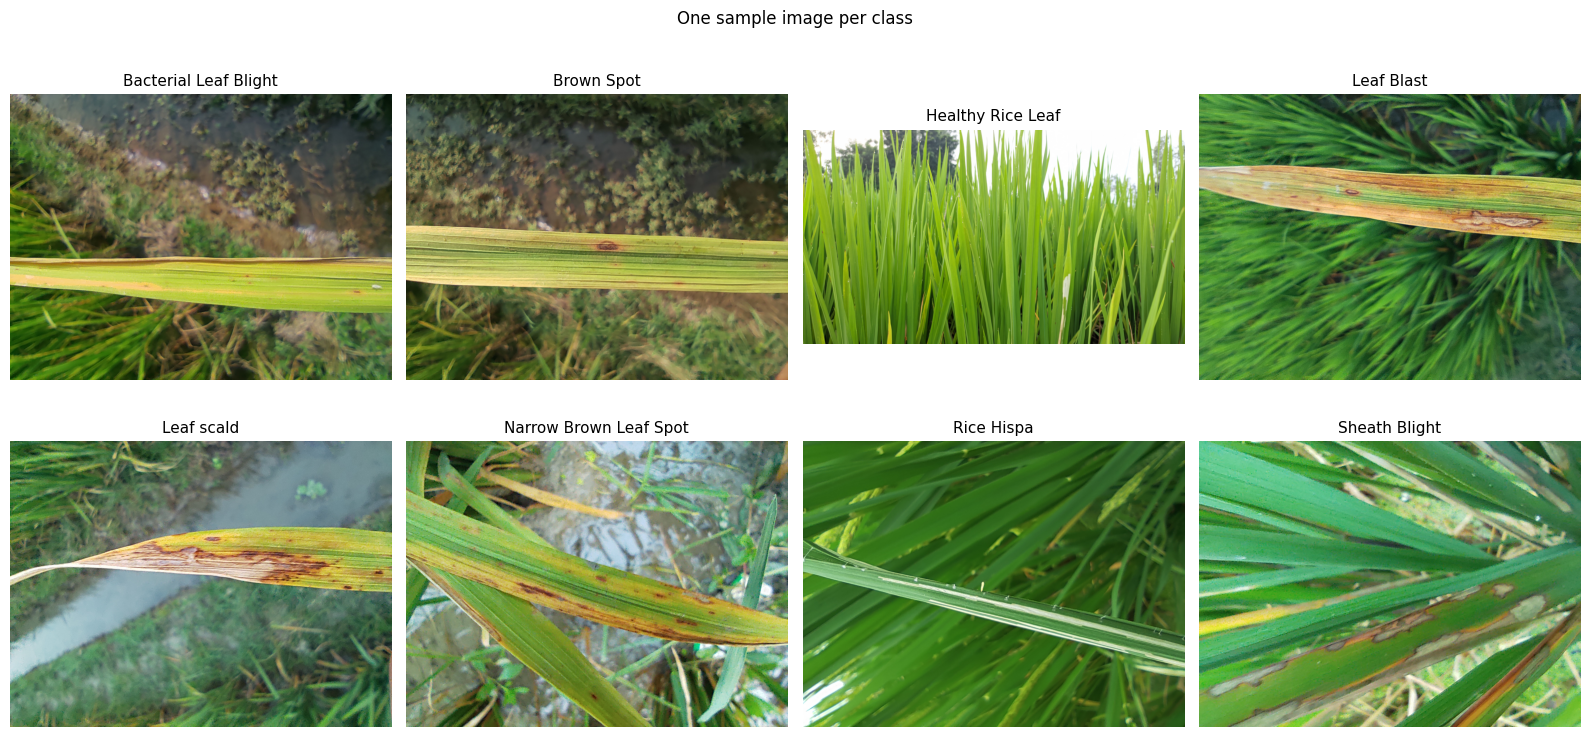

In [ ]:
class_counts = df['label'].value_counts().rename_axis('Class').reset_index(name='Images')
class_counts['Percentage (%)'] = (class_counts['Images'] / len(df) * 100).round(2)
display(class_counts)

plt.figure(figsize=(9, 5))
sns.barplot(data=class_counts, x='Images', y='Class', hue='Class', palette='viridis', legend=False)
plt.title('Number of images per class')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, c in zip(axes.ravel(), classes):
    sample = df[df['label'] == c].sample(1, random_state=SEED).iloc[0]
    ax.imshow(Image.open(sample['filepath']).convert('RGB'))
    ax.set_title(c, fontsize=11); ax.axis('off')
plt.suptitle('One sample image per class'); plt.tight_layout(); plt.show()

### 1.3 Train / validation / test split (70 / 15 / 15)
The split is **stratified**, so every class keeps the same proportion in the three subsets.
First 70% goes to train; the remaining 30% is split 50/50 into validation (15%) and test (15%).
The test set is only used once, in Section 5.

In [ ]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df['label'], random_state=SEED)
val_df,   test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df['label'], random_state=SEED)

print(f'Train: {len(train_df)} ({len(train_df)/len(df):.0%}) | '
      f'Val: {len(val_df)} ({len(val_df)/len(df):.0%}) | Test: {len(test_df)} ({len(test_df)/len(df):.0%})')

split_table = pd.DataFrame({'Train': train_df['label'].value_counts(),
                            'Val':   val_df['label'].value_counts(),
                            'Test':  test_df['label'].value_counts()}).fillna(0).astype(int)
split_table.loc['TOTAL'] = split_table.sum()
display(split_table)

Train: 1190 (70%) | Val: 255 (15%) | Test: 256 (15%)


,Train,Val,Test
label,,,
Bacterial Leaf Blight,126,27,27
Brown Spot,187,40,40
Healthy Rice Leaf,110,24,23
Leaf Blast,213,46,46
Leaf scald,132,28,29
Narrow Brown Leaf Spot,82,18,17
Rice Hispa,150,32,33
Sheath Blight,190,40,41
TOTAL,1190,255,256


### 1.4 Augmentation (train only) and DataLoaders
* `basic` augmentation: horizontal flip + random rotation (±15°). Used for the main models.
* `strong` augmentation: adds vertical flip, random resized crop and colour jitter. Used later as an experiment.
* Validation/test data only receive resize + normalisation (ImageNet mean/std, needed for the pretrained ResNet18 and fine for the scratch CNN).

Batch shape: (32, 3, 224, 224) | labels shape: (32,)


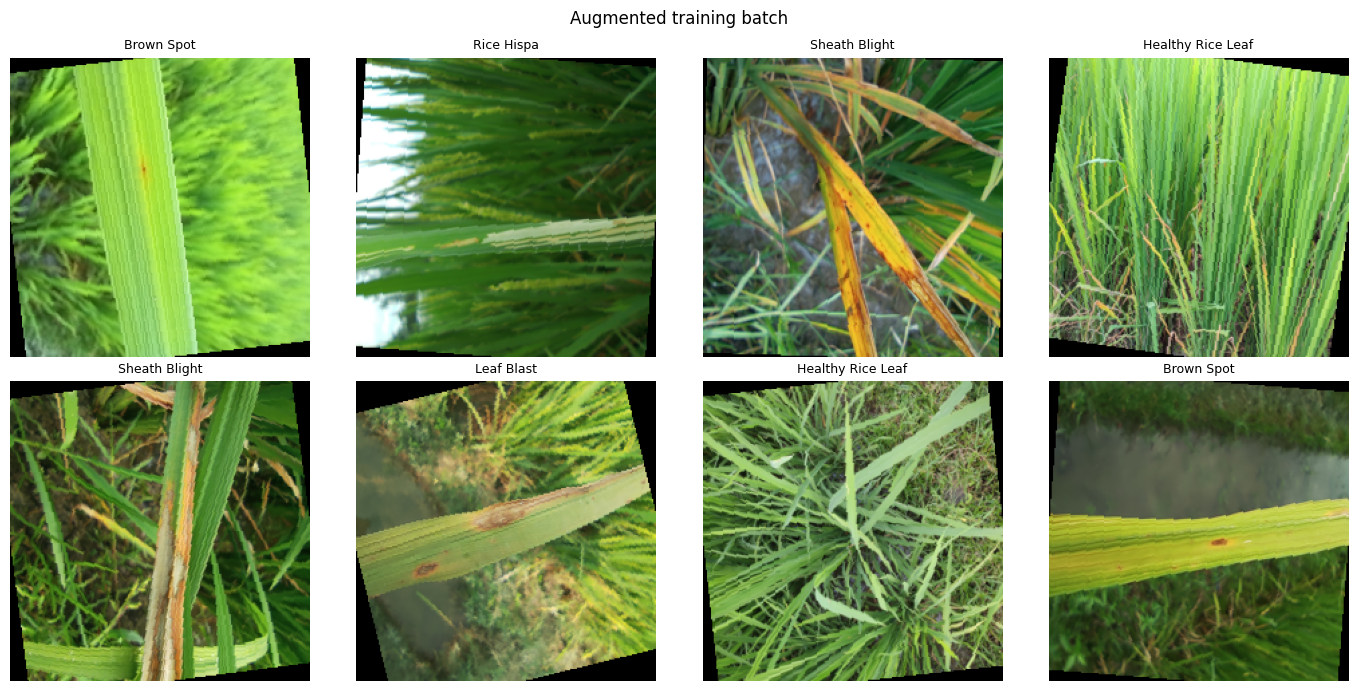

In [ ]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
normalize = transforms.Normalize(MEAN, STD)

def get_train_transform(mode='basic'):
    if mode == 'basic':
        aug = [transforms.Resize((IMG_SIZE, IMG_SIZE)),
               transforms.RandomHorizontalFlip(),
               transforms.RandomRotation(15)]
    elif mode == 'strong':
        aug = [transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
               transforms.RandomHorizontalFlip(),
               transforms.RandomVerticalFlip(),
               transforms.RandomRotation(30),
               transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3)]
    else:
        raise ValueError(mode)
    return transforms.Compose(aug + [transforms.ToTensor(), normalize])

eval_transform = transforms.Compose([transforms.Resize((IMG_SIZE, IMG_SIZE)),
                                     transforms.ToTensor(), normalize])

class RiceDataset(Dataset):
    # Reads an image from disk, converts it to RGB, applies the transform and returns (tensor, label index).
    def __init__(self, dataframe, transform):
        self.paths  = dataframe['filepath'].tolist()
        self.labels = [class_to_idx[l] for l in dataframe['label']]
        self.transform = transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert('RGB')
        return self.transform(img), self.labels[i]

def seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)

def make_loader(dataframe, transform, shuffle):
    g = torch.Generator(); g.manual_seed(SEED)
    return DataLoader(RiceDataset(dataframe, transform), batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=2, worker_init_fn=seed_worker, generator=g)

def get_train_loader(aug='basic'):
    return make_loader(train_df, get_train_transform(aug), shuffle=True)

val_loader  = make_loader(val_df,  eval_transform, shuffle=False)
test_loader = make_loader(test_df, eval_transform, shuffle=False)

# Visual check: one augmented training batch (de-normalised for display)
imgs, lbls = next(iter(get_train_loader('basic')))
print('Batch shape:', tuple(imgs.shape), '| labels shape:', tuple(lbls.shape))
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, im, lb in zip(axes.ravel(), imgs[:8], lbls[:8]):
    im = im * torch.tensor(STD).view(3, 1, 1) + torch.tensor(MEAN).view(3, 1, 1)
    ax.imshow(im.clamp(0, 1).permute(1, 2, 0).numpy()); ax.set_title(classes[lb], fontsize=9); ax.axis('off')
plt.suptitle('Augmented training batch'); plt.tight_layout(); plt.show()

## Shared helpers: training loop, history plot, experiment runner

One training function is used for **every** model so that all results are comparable.
For each epoch it trains, evaluates on the validation set, and keeps the weights with the best
validation accuracy (saved to disk, so the exact same weights can be reloaded for the test set).
Parameters that are frozen (`requires_grad=False`) are simply ignored by the optimizer.

In [ ]:
criterion = nn.CrossEntropyLoss()

def run_epoch(model, loader, optimizer=None):
    # One pass over a loader. If an optimizer is given -> training mode, otherwise evaluation mode.
    train = optimizer is not None
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct    += (out.argmax(1) == y).sum().item()
            n          += x.size(0)
    return total_loss / n, correct / n

def train_model(model, train_loader, optimizer, ckpt_path, epochs=EPOCHS):
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    best_acc, start = -1.0, time.time()
    for ep in range(1, epochs + 1):
        tr_loss, tr_acc = run_epoch(model, train_loader, optimizer)
        va_loss, va_acc = run_epoch(model, val_loader)
        for k, v in zip(history, (tr_loss, tr_acc, va_loss, va_acc)):
            history[k].append(v)
        if va_acc > best_acc:
            best_acc = va_acc
            torch.save(model.state_dict(), ckpt_path)
        print(f'Epoch {ep:02d}/{epochs} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | '
              f'val loss {va_loss:.4f} acc {va_acc:.4f}')
    model.load_state_dict(torch.load(ckpt_path, map_location=device))   # restore best weights
    return history, best_acc, time.time() - start

def plot_history(history, title):
    ep = range(1, len(history['train_loss']) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(ep, history['train_loss'], 'o-', label='Train'); ax[0].plot(ep, history['val_loss'], 'o-', label='Validation')
    ax[0].set(title=f'Loss – {title}', xlabel='Epoch', ylabel='Loss'); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(ep, history['train_acc'], 'o-', label='Train'); ax[1].plot(ep, history['val_acc'], 'o-', label='Validation')
    ax[1].set(title=f'Accuracy – {title}', xlabel='Epoch', ylabel='Accuracy'); ax[1].legend(); ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.show()

def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

## 2. CNN from Scratch

Architecture: **4 convolutional blocks** (requirement: 3–5), each = `Conv 3×3 → BatchNorm → ReLU → MaxPool 2×2`,
with 32 → 64 → 128 → 256 filters. The 224×224 input is reduced to a 14×14×256 feature map, which is flattened and sent
through a fully connected layer (512 units) with dropout, then the output layer (8 classes).
BatchNorm stabilises and speeds up training; dropout reduces over-fitting of the dense layer.

In [ ]:
class CNNScratch(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, dropout=0.5):
        super().__init__()
        def block(cin, cout):
            return [nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(), nn.MaxPool2d(2, 2)]
        self.features = nn.Sequential(*block(3, 32), *block(32, 64), *block(64, 128), *block(128, 256))  # 224 -> 14
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 14 * 14, 512), nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(512, num_classes))
    def forward(self, x):
        return self.classifier(self.features(x))

def build_scratch(dropout=0.5):
    return CNNScratch(dropout=dropout).to(device)

summary(build_scratch(), input_size=(1, 3, IMG_SIZE, IMG_SIZE), col_names=('input_size', 'output_size', 'num_params'))

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
CNNScratch                               [1, 3, 224, 224]          [1, 8]                    --
├─Sequential: 1-1                        [1, 3, 224, 224]          [1, 256, 14, 14]          --
│    └─Conv2d: 2-1                       [1, 3, 224, 224]          [1, 32, 224, 224]         896
│    └─BatchNorm2d: 2-2                  [1, 32, 224, 224]         [1, 32, 224, 224]         64
│    └─ReLU: 2-3                         [1, 32, 224, 224]         [1, 32, 224, 224]         --
│    └─MaxPool2d: 2-4                    [1, 32, 224, 224]         [1, 32, 112, 112]         --
│    └─Conv2d: 2-5                       [1, 32, 112, 112]         [1, 64, 112, 112]         18,496
│    └─BatchNorm2d: 2-6                  [1, 64, 112, 112]         [1, 64, 112, 112]         128
│    └─ReLU: 2-7                         [1, 64, 112, 112]         [1, 64, 112, 112]         --
│    └─MaxPool2d: 2-8        

### 2.1 Train the baseline scratch model
Baseline settings: Adam, learning rate `1e-3`, dropout `0.5`, basic augmentation, `EPOCHS` epochs.
`results` collects one row per training run (used for the tables in Sections 3–5).

In [ ]:
results, histories = [], {}     # results: list of dicts (one per run) | histories: run name -> curves

def run_experiment(approach, name, lr, dropout, aug):
    # Build a fresh model, train it with the given settings and log the outcome.
    set_seed()
    model = build_scratch(dropout) if approach == 'Scratch CNN' else build_resnet(dropout)
    opt = optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    ckpt = os.path.join(CKPT_DIR, f"{approach.replace(' ', '_')}_{name}.pth")
    print(f'\n=== {approach} | {name} | lr={lr} dropout={dropout} aug={aug} ===')
    hist, best_val, secs = train_model(model, get_train_loader(aug), opt, ckpt)
    _, trainable = count_params(model)
    best_ep = int(np.argmax(hist['val_acc'])) + 1
    results.append({'Approach': approach, 'Run': name, 'LR': lr, 'Dropout': dropout, 'Augmentation': aug,
                    'Best Val Acc': round(best_val, 4), 'Val Loss @best': round(hist['val_loss'][best_ep - 1], 4),
                    'Train Acc @best': round(hist['train_acc'][best_ep - 1], 4), 'Best Epoch': best_ep,
                    'Trainable Params': trainable, 'Time (s)': round(secs), 'ckpt': ckpt})
    histories[(approach, name)] = hist
    return model, hist


=== Scratch CNN | baseline | lr=0.001 dropout=0.5 aug=basic ===
Epoch 01/10 | train loss 8.8457 acc 0.2403 | val loss 1.7604 acc 0.3294
Epoch 02/10 | train loss 1.8325 acc 0.3269 | val loss 1.6061 acc 0.4275
Epoch 03/10 | train loss 1.7022 acc 0.3714 | val loss 1.4578 acc 0.5020
Epoch 04/10 | train loss 1.6479 acc 0.3849 | val loss 1.3457 acc 0.5529
Epoch 05/10 | train loss 1.5934 acc 0.3958 | val loss 1.3133 acc 0.4980
Epoch 06/10 | train loss 1.5629 acc 0.4042 | val loss 1.4030 acc 0.4980
Epoch 07/10 | train loss 1.5770 acc 0.4244 | val loss 1.3195 acc 0.5608
Epoch 08/10 | train loss 1.4664 acc 0.4496 | val loss 1.2589 acc 0.5608
Epoch 09/10 | train loss 1.4509 acc 0.4546 | val loss 1.1815 acc 0.5412
Epoch 10/10 | train loss 1.4682 acc 0.4445 | val loss 1.1282 acc 0.6000


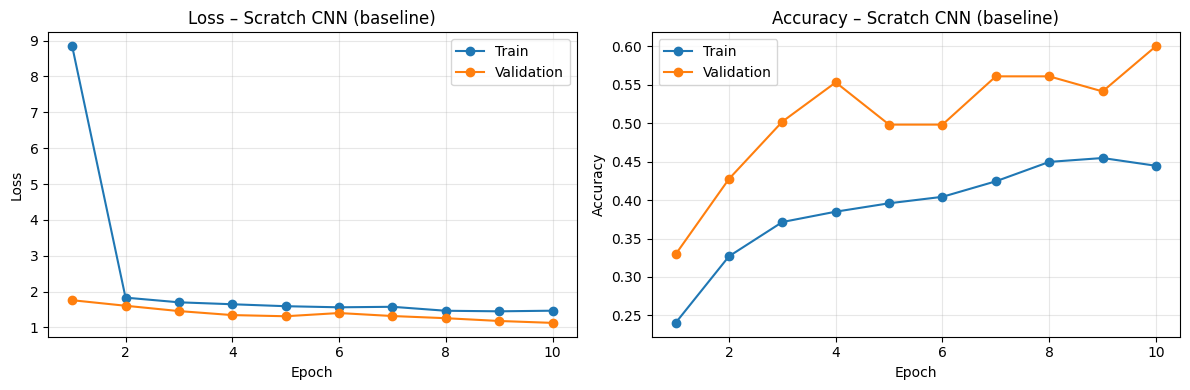

In [ ]:
model_scratch, hist_scratch = run_experiment('Scratch CNN', 'baseline', lr=1e-3, dropout=0.5, aug='basic')
plot_history(hist_scratch, 'Scratch CNN (baseline)')

## 3. Transfer Learning with ResNet18
ResNet18 pretrained on ImageNet is loaded and its final layer is replaced by `Dropout → Linear(512, 8)`.
All layers are **fine-tuned** with a small learning rate (`1e-4`) so the pretrained features are adapted
gently to rice-leaf images (a large learning rate would destroy them).

In [ ]:
def build_resnet(dropout=0.5):
    m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    m.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(m.fc.in_features, NUM_CLASSES))
    return m.to(device)

summary(build_resnet(), input_size=(1, 3, IMG_SIZE, IMG_SIZE), depth=2, col_names=('output_size', 'num_params'))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 101MB/s]


Layer (type:depth-idx)                   Output Shape              Param #
ResNet                                   [1, 8]                    --
├─Conv2d: 1-1                            [1, 64, 112, 112]         9,408
├─BatchNorm2d: 1-2                       [1, 64, 112, 112]         128
├─ReLU: 1-3                              [1, 64, 112, 112]         --
├─MaxPool2d: 1-4                         [1, 64, 56, 56]           --
├─Sequential: 1-5                        [1, 64, 56, 56]           --
│    └─BasicBlock: 2-1                   [1, 64, 56, 56]           73,984
│    └─BasicBlock: 2-2                   [1, 64, 56, 56]           73,984
├─Sequential: 1-6                        [1, 128, 28, 28]          --
│    └─BasicBlock: 2-3                   [1, 128, 28, 28]          230,144
│    └─BasicBlock: 2-4                   [1, 128, 28, 28]          295,424
├─Sequential: 1-7                        [1, 256, 14, 14]          --
│    └─BasicBlock: 2-5                   [1, 256, 14, 14]      


=== ResNet18 | baseline | lr=0.0001 dropout=0.5 aug=basic ===
Epoch 01/10 | train loss 1.6646 acc 0.4176 | val loss 1.0649 acc 0.6588
Epoch 02/10 | train loss 0.9321 acc 0.6815 | val loss 0.7208 acc 0.7647
Epoch 03/10 | train loss 0.6054 acc 0.7933 | val loss 0.6011 acc 0.8000
Epoch 04/10 | train loss 0.4903 acc 0.8496 | val loss 0.5479 acc 0.8157
Epoch 05/10 | train loss 0.3587 acc 0.8857 | val loss 0.5022 acc 0.8392
Epoch 06/10 | train loss 0.2831 acc 0.9042 | val loss 0.4787 acc 0.8471
Epoch 07/10 | train loss 0.2137 acc 0.9445 | val loss 0.4200 acc 0.8510
Epoch 08/10 | train loss 0.1635 acc 0.9555 | val loss 0.4024 acc 0.8588
Epoch 09/10 | train loss 0.1345 acc 0.9706 | val loss 0.4385 acc 0.8824
Epoch 10/10 | train loss 0.1007 acc 0.9748 | val loss 0.3680 acc 0.8745


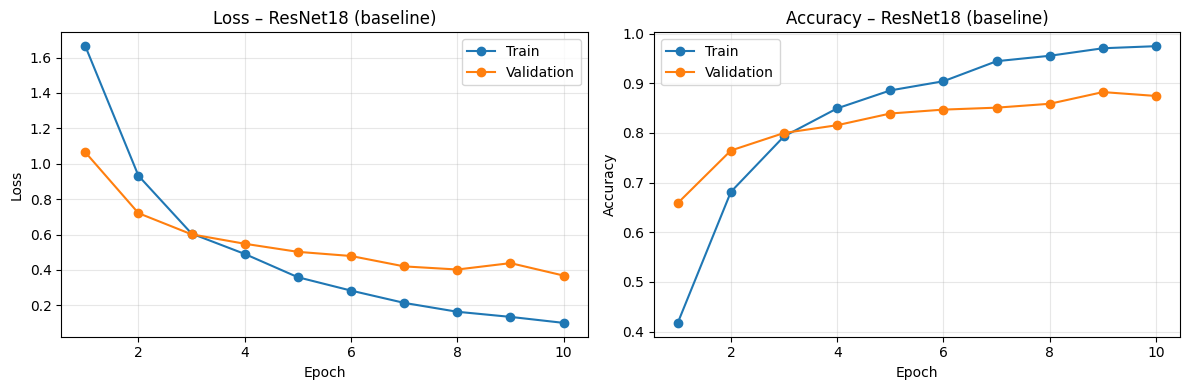

In [ ]:
model_resnet, hist_resnet = run_experiment('ResNet18', 'baseline', lr=1e-4, dropout=0.5, aug='basic')
plot_history(hist_resnet, 'ResNet18 (baseline)')

### 3.1 Baseline comparison: scratch CNN vs. ResNet18 (validation set)

,LR,Dropout,Augmentation,Best Val Acc,Val Loss @best,Train Acc @best,Best Epoch,Trainable Params,Time (s),Total Params
Approach,,,,,,,,,,
Scratch CNN,0.0010,0.5,basic,0.6000,1.1282,0.4445,10,26084104,3225,26084104
ResNet18,0.0001,0.5,basic,0.8824,0.4385,0.9706,9,11180616,3791,11180616


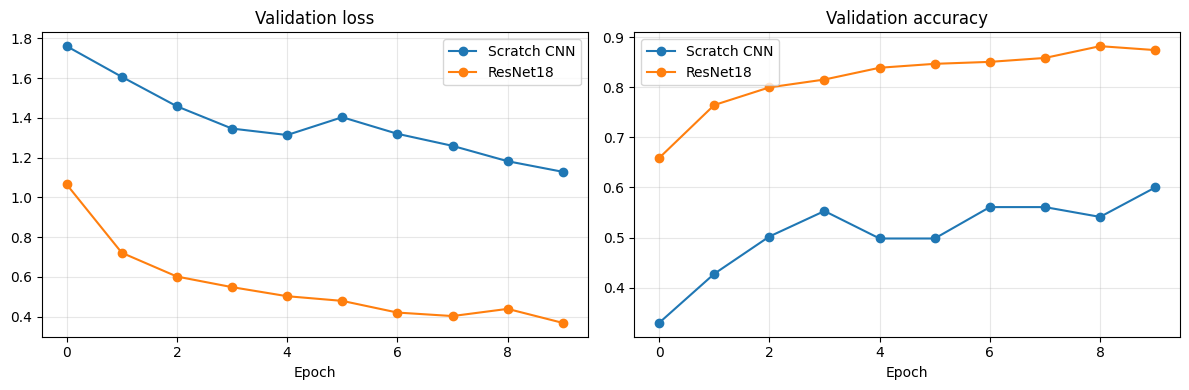

In [ ]:
base = pd.DataFrame([r for r in results if r['Run'] == 'baseline'])
tot = {'Scratch CNN': count_params(build_scratch())[0], 'ResNet18': count_params(build_resnet())[0]}
base['Total Params'] = base['Approach'].map(tot)
display(base.drop(columns=['ckpt', 'Run']).set_index('Approach'))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for k in ['Scratch CNN', 'ResNet18']:
    h = histories[(k, 'baseline')]
    ax[0].plot(h['val_loss'], 'o-', label=k); ax[1].plot(h['val_acc'], 'o-', label=k)
ax[0].set(title='Validation loss', xlabel='Epoch'); ax[1].set(title='Validation accuracy', xlabel='Epoch')
for a in ax: a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 4. Experiments

Three settings are changed, **one at a time** relative to each approach's baseline (so each effect can be isolated):

| Setting | Scratch CNN (baseline → changed) | ResNet18 (baseline → changed) |
|---|---|---|
| Learning rate | 1e-3 → **1e-4** | 1e-4 → **1e-3** |
| Dropout | 0.5 → **0.3** | 0.5 → **0.2** |
| Augmentation | basic → **strong** | basic → **strong** |

Model selection uses the **validation** accuracy only; the test set stays untouched until Section 5.
(Expect roughly 6 extra training runs; with `DEBUG = False` on a GPU this takes a while.)

In [ ]:
experiments = {
    'Scratch CNN': [('lr_1e-4',       1e-4, 0.5, 'basic'),
                    ('dropout_0.3',   1e-3, 0.3, 'basic'),
                    ('strong_aug',    1e-3, 0.5, 'strong')],
    'ResNet18':    [('lr_1e-3',       1e-3, 0.5, 'basic'),
                    ('dropout_0.2',   1e-4, 0.2, 'basic'),
                    ('strong_aug',    1e-4, 0.5, 'strong')],
}
for approach, runs in experiments.items():
    for name, lr, dr, aug in runs:
        run_experiment(approach, name, lr, dr, aug)


=== Scratch CNN | lr_1e-4 | lr=0.0001 dropout=0.5 aug=basic ===
Epoch 01/10 | train loss 2.2159 acc 0.2882 | val loss 1.5552 acc 0.4353
Epoch 02/10 | train loss 1.5386 acc 0.4513 | val loss 1.2476 acc 0.5725
Epoch 03/10 | train loss 1.3959 acc 0.5176 | val loss 1.0996 acc 0.6588
Epoch 04/10 | train loss 1.3328 acc 0.5412 | val loss 1.0644 acc 0.6392
Epoch 05/10 | train loss 1.2025 acc 0.5849 | val loss 0.9783 acc 0.6588
Epoch 06/10 | train loss 1.1885 acc 0.5748 | val loss 0.9687 acc 0.6510
Epoch 07/10 | train loss 1.0970 acc 0.6261 | val loss 0.9309 acc 0.6745
Epoch 08/10 | train loss 1.0408 acc 0.6370 | val loss 0.8444 acc 0.6902
Epoch 09/10 | train loss 1.0006 acc 0.6588 | val loss 0.8699 acc 0.7098
Epoch 10/10 | train loss 0.9833 acc 0.6613 | val loss 0.8091 acc 0.7098

=== Scratch CNN | dropout_0.3 | lr=0.001 dropout=0.3 aug=basic ===
Epoch 01/10 | train loss 9.5309 acc 0.2420 | val loss 1.6976 acc 0.4000
Epoch 02/10 | train loss 1.6994 acc 0.3866 | val loss 1.4946 acc 0.4784
Epo


Experiment results – Scratch CNN


,Run,LR,Dropout,Augmentation,Best Val Acc,Val Loss @best,Train Acc @best,Best Epoch,Time (s)
0,baseline,0.0010,0.5,basic,0.6000,1.1282,0.4445,10,3225
1,lr_1e-4,0.0001,0.5,basic,0.7098,0.8699,0.6588,9,3051
2,dropout_0.3,0.0010,0.3,basic,0.6510,1.0045,0.5697,10,3168
3,strong_aug,0.0010,0.5,strong,0.4392,1.5674,0.3118,6,3212



Experiment results – ResNet18


,Run,LR,Dropout,Augmentation,Best Val Acc,Val Loss @best,Train Acc @best,Best Epoch,Time (s)
0,baseline,0.0001,0.5,basic,0.8824,0.4385,0.9706,9,3791
1,lr_1e-3,0.0010,0.5,basic,0.7843,0.6995,0.8311,8,3856
2,dropout_0.2,0.0001,0.2,basic,0.8745,0.3829,0.9580,7,3729
3,strong_aug,0.0001,0.5,strong,0.8392,0.4707,0.8563,8,3788


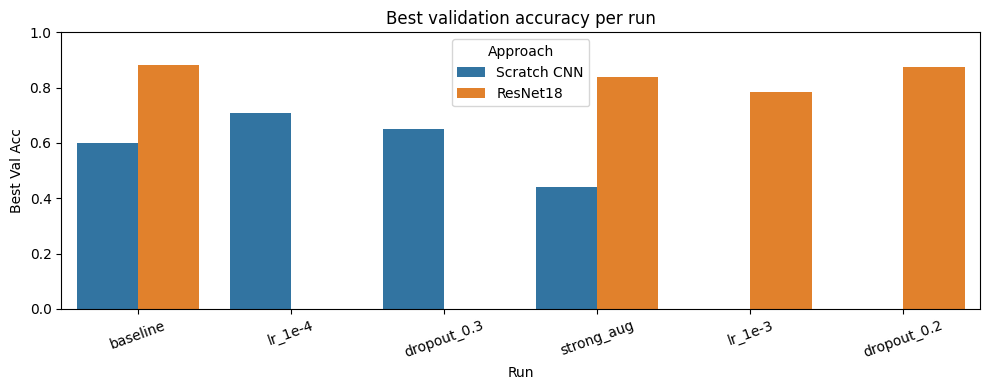

Selected configuration per approach (highest validation accuracy):


,Run,LR,Dropout,Augmentation,Best Val Acc
Approach,,,,,
ResNet18,baseline,0.0001,0.5,basic,0.8824
Scratch CNN,lr_1e-4,0.0001,0.5,basic,0.7098


In [ ]:
res_df = pd.DataFrame(results)
show_cols = ['Run', 'LR', 'Dropout', 'Augmentation', 'Best Val Acc', 'Val Loss @best', 'Train Acc @best', 'Best Epoch', 'Time (s)']
for approach in ['Scratch CNN', 'ResNet18']:
    print(f'\nExperiment results – {approach}')
    display(res_df[res_df['Approach'] == approach][show_cols].reset_index(drop=True))

# Bar chart of validation accuracy for all runs
plt.figure(figsize=(10, 4))
sns.barplot(data=res_df, x='Run', y='Best Val Acc', hue='Approach')
plt.ylim(0, 1); plt.title('Best validation accuracy per run'); plt.xticks(rotation=20); plt.tight_layout(); plt.show()

# Best configuration of each approach (by validation accuracy)
best_rows = res_df.loc[res_df.groupby('Approach')['Best Val Acc'].idxmax()].set_index('Approach')
print('Selected configuration per approach (highest validation accuracy):')
display(best_rows[['Run', 'LR', 'Dropout', 'Augmentation', 'Best Val Acc']])

## 5. Evaluation on the Test Set

The best checkpoint of each approach (chosen on validation accuracy in Section 4) is reloaded and evaluated **once** on the test set.
Reported: accuracy, macro precision / recall / F1 (each class counts equally, important with imbalanced classes),
per-class report and confusion matrix.

In [ ]:
def load_best(approach):
    row = best_rows.loc[approach]
    m = build_scratch(row['Dropout']) if approach == 'Scratch CNN' else build_resnet(row['Dropout'])
    m.load_state_dict(torch.load(row['ckpt'], map_location=device))
    return m.eval()

@torch.no_grad()
def predict(model, loader):
    ys, ps = [], []
    for x, y in loader:
        ps.extend(model(x.to(device)).argmax(1).cpu().tolist()); ys.extend(y.tolist())
    return np.array(ys), np.array(ps)

final_models, preds = {}, {}
for approach in ['Scratch CNN', 'ResNet18']:
    final_models[approach] = load_best(approach)
    preds[approach] = predict(final_models[approach], test_loader)

rows = []
for approach, (y, p) in preds.items():
    rows.append({'Approach': approach, 'Config': best_rows.loc[approach, 'Run'],
                 'Accuracy': accuracy_score(y, p),
                 'Precision (macro)': precision_score(y, p, average='macro', zero_division=0),
                 'Recall (macro)':    recall_score(y, p, average='macro', zero_division=0),
                 'F1 (macro)':        f1_score(y, p, average='macro', zero_division=0),
                 'F1 (weighted)':     f1_score(y, p, average='weighted', zero_division=0)})
test_table = pd.DataFrame(rows).set_index('Approach')
display(test_table.round(4))

,Config,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 (weighted)
Approach,,,,,,
Scratch CNN,lr_1e-4,0.6719,0.6457,0.6349,0.6289,0.6573
ResNet18,baseline,0.8828,0.8776,0.8649,0.8693,0.8818



===== Scratch CNN: classification report (test set) =====
                        precision    recall  f1-score   support

 Bacterial Leaf Blight      0.613     0.704     0.655        27
            Brown Spot      0.750     0.675     0.711        40
     Healthy Rice Leaf      0.857     0.783     0.818        23
            Leaf Blast      0.587     0.587     0.587        46
            Leaf scald      0.727     0.552     0.627        29
Narrow Brown Leaf Spot      0.200     0.059     0.091        17
            Rice Hispa      0.844     0.818     0.831        33
         Sheath Blight      0.587     0.902     0.712        41

              accuracy                          0.672       256
             macro avg      0.646     0.635     0.629       256
          weighted avg      0.663     0.672     0.657       256


===== ResNet18: classification report (test set) =====
                        precision    recall  f1-score   support

 Bacterial Leaf Blight      0.917     0.815     0

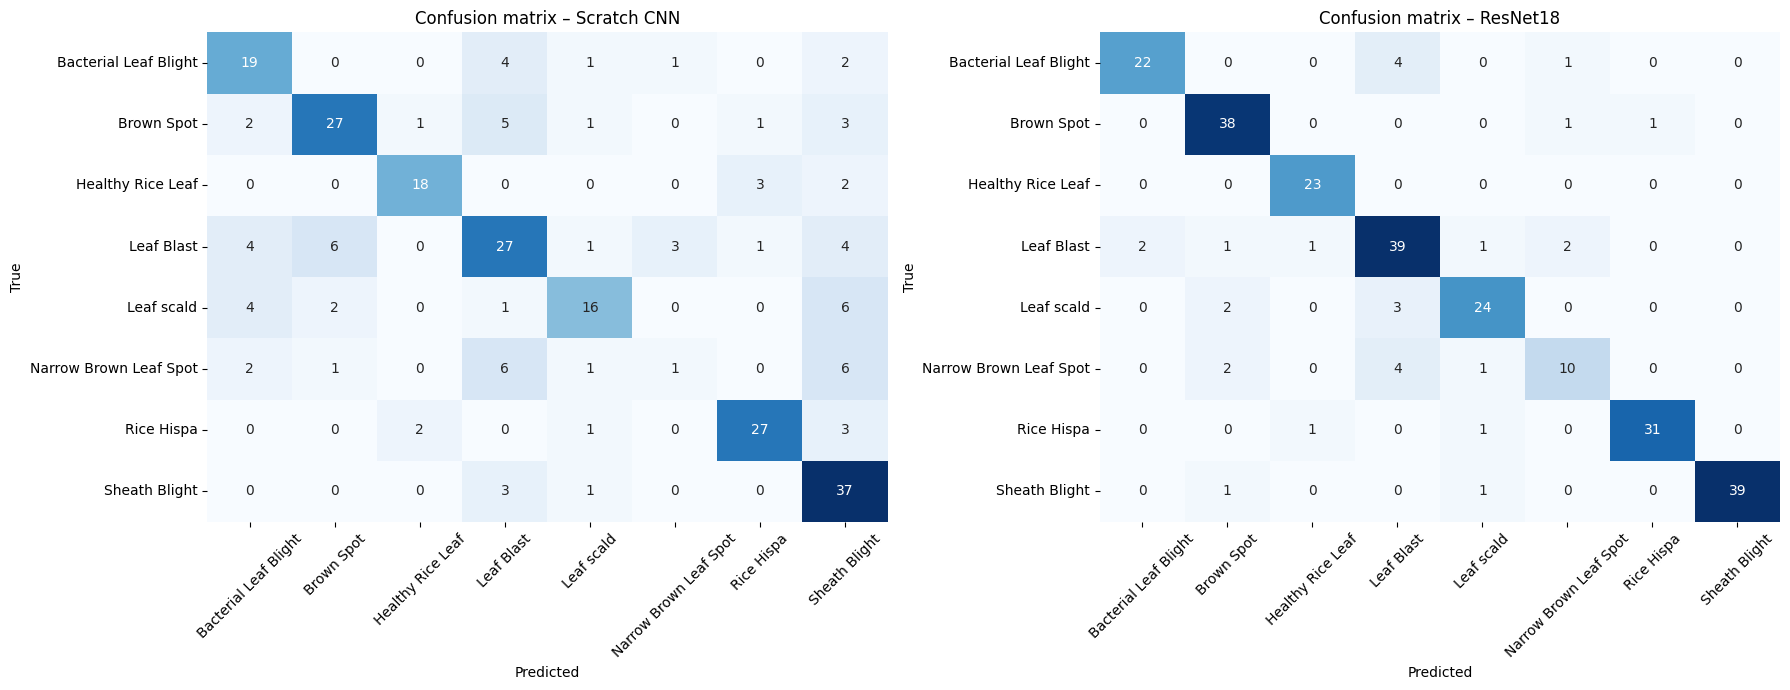

In [ ]:
for approach, (y, p) in preds.items():
    print(f'\n===== {approach}: classification report (test set) =====')
    print(classification_report(y, p, target_names=classes, digits=3, zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, (approach, (y, p)) in zip(axes, preds.items()):
    cm = confusion_matrix(y, p, labels=range(NUM_CLASSES))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes, ax=ax, cbar=False)
    ax.set(title=f'Confusion matrix – {approach}', xlabel='Predicted', ylabel='True')
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

In [ ]:
# Automatic helper for the written analysis: weakest classes and most frequent confusions per model
for approach, (y, p) in preds.items():
    f1s = f1_score(y, p, average=None, labels=range(NUM_CLASSES), zero_division=0)
    order = np.argsort(f1s)
    print(f'\n{approach}: lowest-F1 classes -> ' + ', '.join(f'{classes[i]} ({f1s[i]:.2f})' for i in order[:3]))
    cm = confusion_matrix(y, p, labels=range(NUM_CLASSES)); np.fill_diagonal(cm, 0)
    top = np.dstack(np.unravel_index(np.argsort(cm.ravel())[::-1][:3], cm.shape))[0]
    print('   most frequent confusions (true -> predicted): ' +
          '; '.join(f'{classes[t]} -> {classes[q]} ({cm[t, q]}x)' for t, q in top))


Scratch CNN: lowest-F1 classes -> Narrow Brown Leaf Spot (0.09), Leaf Blast (0.59), Leaf scald (0.63)
   most frequent confusions (true -> predicted): Narrow Brown Leaf Spot -> Leaf Blast (6x); Leaf scald -> Sheath Blight (6x); Narrow Brown Leaf Spot -> Sheath Blight (6x)

ResNet18: lowest-F1 classes -> Narrow Brown Leaf Spot (0.65), Leaf Blast (0.81), Leaf scald (0.84)
   most frequent confusions (true -> predicted): Narrow Brown Leaf Spot -> Leaf Blast (4x); Bacterial Leaf Blight -> Leaf Blast (4x); Leaf scald -> Leaf Blast (3x)


### 5.1 Misclassified test images with Grad-CAM (Explainable AI)

Grad-CAM highlights the image regions that contributed most to the **predicted** class
(red/yellow = high influence, blue = low). For wrongly predicted images it shows *what the model looked at* when it made the mistake,
e.g. background or soil instead of the lesion on the leaf.

* Target layer for ResNet18: last block of `layer4`.
* Target layer for the scratch CNN: the last ReLU of the 4th conv block.

ResNet18: 30 misclassified of 256 test images; showing 8.


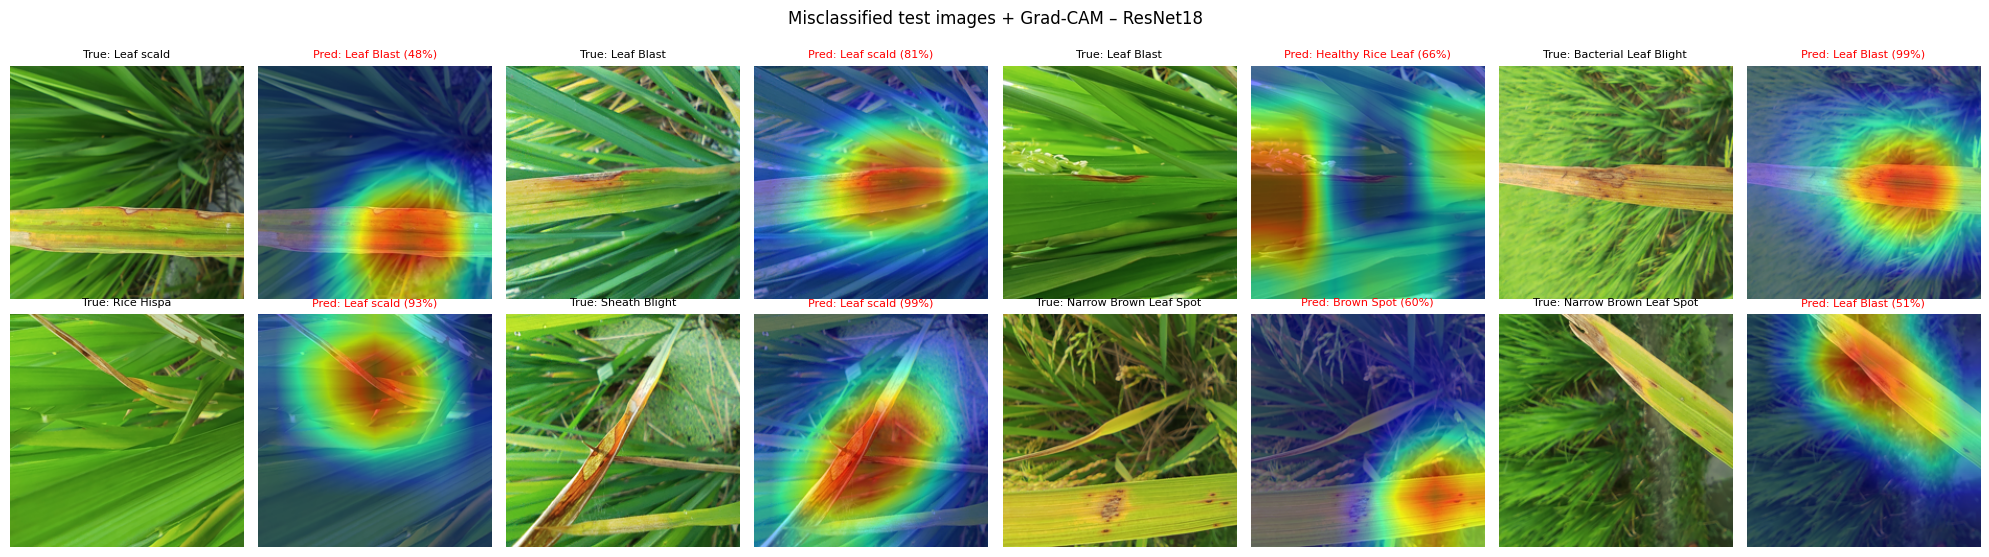

Scratch CNN: 84 misclassified of 256 test images; showing 8.


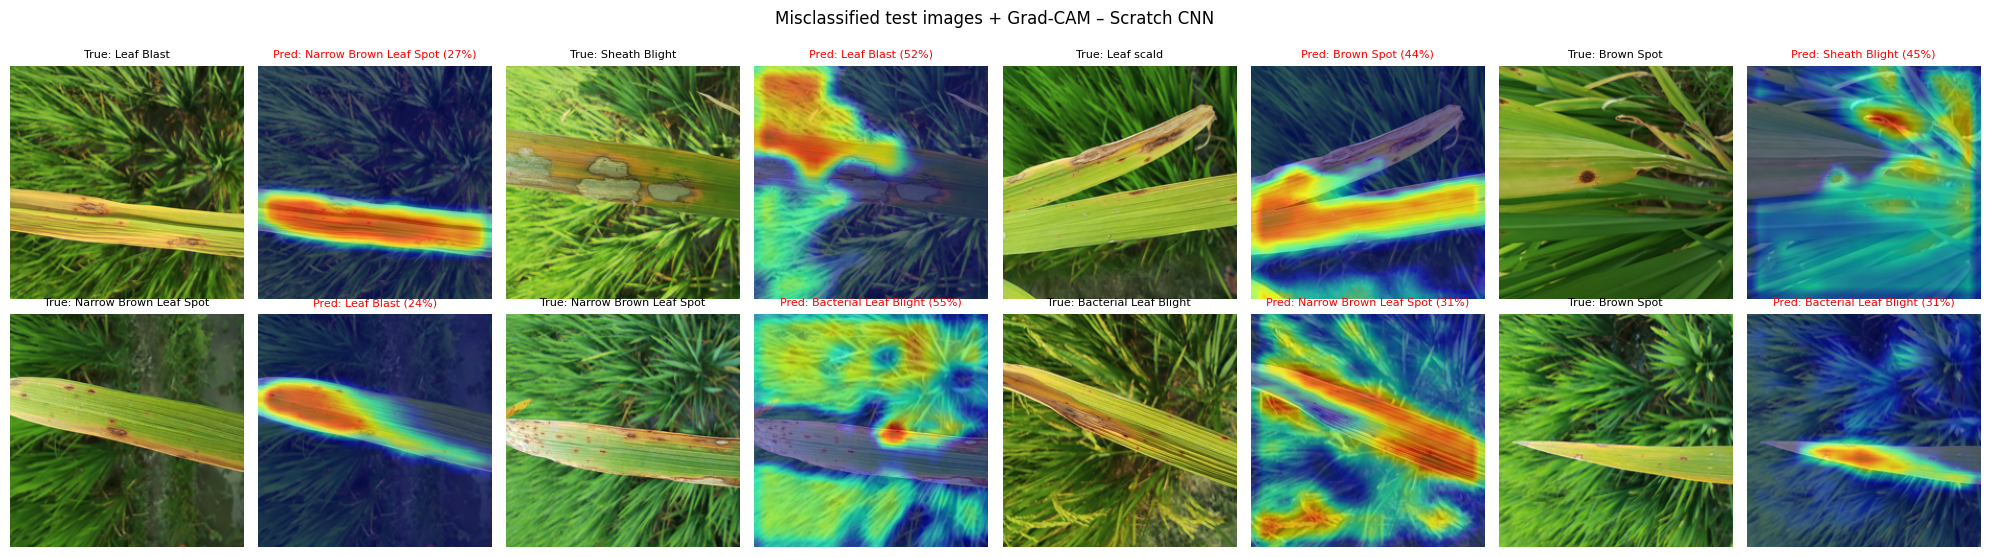

In [ ]:
def gradcam_misclassified(approach, target_layer, n=8):
    model = final_models[approach]
    y, p = preds[approach]
    wrong = np.where(y != p)[0]
    print(f'{approach}: {len(wrong)} misclassified of {len(y)} test images; showing {min(n, len(wrong))}.')
    if len(wrong) == 0:
        return
    rng = np.random.RandomState(SEED)
    chosen = rng.choice(wrong, size=min(n, len(wrong)), replace=False)

    cols = 4
    rows_n = int(np.ceil(len(chosen) / cols))
    fig, axes = plt.subplots(rows_n, cols * 2, figsize=(cols * 5, rows_n * 2.8))
    axes = np.atleast_2d(axes)
    for a in axes.ravel(): a.axis('off')

    with GradCAM(model=model, target_layers=[target_layer]) as cam:
        for k, idx in enumerate(chosen):
            path = test_df.iloc[idx]['filepath']
            pil = Image.open(path).convert('RGB').resize((IMG_SIZE, IMG_SIZE))
            x = eval_transform(pil).unsqueeze(0).to(device)
            pred_cls = int(p[idx])
            gray = cam(input_tensor=x, targets=[ClassifierOutputTarget(pred_cls)])[0]
            overlay = show_cam_on_image(np.float32(np.array(pil)) / 255., gray, use_rgb=True)
            with torch.no_grad():
                conf = torch.softmax(model(x), 1)[0, pred_cls].item()
            r, c = divmod(k, cols)
            axes[r, 2 * c].imshow(pil);        axes[r, 2 * c].set_title(f'True: {classes[y[idx]]}', fontsize=8)
            axes[r, 2 * c + 1].imshow(overlay); axes[r, 2 * c + 1].set_title(f'Pred: {classes[pred_cls]} ({conf:.0%})', fontsize=8, color='red')
    plt.suptitle(f'Misclassified test images + Grad-CAM – {approach}', y=1.0)
    plt.tight_layout(); plt.show()

gradcam_misclassified('ResNet18',    final_models['ResNet18'].layer4[-1])
gradcam_misclassified('Scratch CNN', final_models['Scratch CNN'].features[-2])

### 5.2 Analisis dan Kesimpulan

**Catatan pengaturan.** Seluruh pelatihan dijalankan di **CPU** dengan konfigurasi penuh (citra 224×224, 10 epoch per run, satu seed = 42, satu kali pelatihan per konfigurasi). Satu run memakan sekitar 50–65 menit. Karena ukuran validasi hanya 255 citra, selisih 1 citra setara ±0,4%; selisih di bawah ±2% sebaiknya tidak dianggap pasti.

**a) Perbandingan CNN Scratch vs ResNet18 (data uji, 256 citra).**

| Model | Konfigurasi terpilih | Akurasi | Precision (macro) | Recall (macro) | F1 (macro) | Salah prediksi |
|---|---|---|---|---|---|---|
| CNN Scratch | `lr_1e-4` | 67,19% | 0,646 | 0,635 | 0,629 | 84 |
| ResNet18 | baseline (lr 1e-4, dropout 0,5) | **88,28%** | **0,878** | **0,865** | **0,869** | 30 |

ResNet18 unggul sekitar **21 poin persentase** dalam akurasi dan sekitar 0,24 dalam F1-macro. Penyebab utamanya: ResNet18 memulai dari bobot ImageNet yang sudah mengenal tepi, tekstur, dan bentuk, sehingga hanya perlu menyesuaikan fitur tersebut, sedangkan CNN scratch harus mempelajari semuanya dari 1.190 citra latih. Selain itu, ResNet18 jauh lebih efisien: parameternya hanya 11,18 juta dibandingkan 26,08 juta pada scratch. Pada CNN scratch, 25,69 juta parameter (sekitar 98,5%) berada pada satu lapisan fully connected (50.176 → 512), yang membuat model mudah menghafal dan boros parameter, tetapi tidak banyak belajar fitur visual. Waktu latih per run kedua model hampir sama (scratch ±3.050–3.225 detik, ResNet18 ±3.730–3.860 detik). Akurasi uji hampir sama dengan akurasi validasi (ResNet18: 88,2% vs 88,3%), sehingga pemilihan model lewat validasi dapat dianggap tidak bocor dan hasilnya stabil.

**b) Pengaruh eksperimen (akurasi validasi terbaik).**

| Pengaturan | CNN Scratch | ResNet18 |
|---|---|---|
| Baseline | 60,00% (lr 1e-3, dropout 0,5, augmentasi dasar) | 88,24% (lr 1e-4, dropout 0,5, augmentasi dasar) |
| Learning rate | **71,0%** (lr 1e-4) | 78,4% (lr 1e-3) |
| Dropout | 65,1% (0,3) | 87,5% (0,2) |
| Augmentasi kuat | 43,9% | 83,9% |

* **Learning rate** adalah pengaturan yang paling berpengaruh. Pada CNN scratch, lr 1e-3 membuat pelatihan tidak stabil (loss epoch pertama sangat tinggi, 7,7–9,5), sehingga menurunkan lr menjadi 1e-4 menaikkan akurasi validasi sekitar 11 poin. Sebaliknya pada ResNet18, lr besar (1e-3) merusak bobot pralatih dan menurunkan akurasi sekitar 10 poin (val loss terbaik 0,70 vs 0,44 pada baseline). Jadi fine-tuning membutuhkan lr kecil.
* **Dropout:** pada ResNet18 dropout 0,2 vs 0,5 hanya berbeda sekitar 2 citra (87,5% vs 88,2%), sehingga tidak ada bukti perbedaan yang berarti. Pada scratch, dropout 0,3 menaikkan akurasi validasi dari 60,0% ke 65,1%; kenaikan ini searah dengan dugaan bahwa dropout 0,5 terlalu kuat untuk model yang masih underfitting, tetapi karena pelatihan pada lr 1e-3 tidak stabil dan hanya satu seed, efeknya belum dapat dipastikan.
* **Augmentasi kuat** menurunkan kedua model. Pada scratch, akurasi latih hanya sekitar 31% (underfitting): augmentasi yang lebih berat membuat tugas lebih sulit, sementara 10 epoch belum cukup. Pada ResNet18 selisih latih–validasi menyempit, tetapi akurasi validasi turun ke 83,9%. Dengan epoch yang lebih banyak, augmentasi kuat mungkin dapat membantu, tetapi itu belum diuji.

**c) Overfitting dan underfitting.** ResNet18 baseline mencapai akurasi latih sekitar 97% dan validasi sekitar 88%, selisih sekitar 10 poin dan akurasi validasi terbaik dicapai pada epoch 9, tanda overfitting ringan hingga sedang yang wajar untuk dataset kecil. CNN scratch baseline justru **underfitting**: akurasi latih (44%) lebih rendah daripada validasi (60%), karena kombinasi dropout, augmentasi, dan optimasi yang tidak stabil pada lr 1e-3. Karena itu bobot terbaik diambil dari epoch dengan akurasi validasi tertinggi (checkpoint), bukan epoch terakhir.

**d) Hasil per kelas dan confusion matrix.** Pada ResNet18 kelas yang paling mudah adalah *Sheath Blight* (F1 0,975), *Healthy Rice Leaf* (0,958), dan *Rice Hispa* (0,954). Kelas tersulit adalah ***Narrow Brown Leaf Spot*** (F1 0,645; recall 0,588), dan pada CNN scratch hampir tidak dikenali (F1 0,091; recall 0,059). Penyebabnya:
1. Kelas ini paling sedikit datanya (117 citra, 6,9% dari total; hanya 82 citra latih).
2. Gejalanya berupa bercak cokelat kecil dan sempit yang mirip dengan *Brown Spot*, *Leaf Blast*, dan *Sheath Blight*.

Kesalahan terbanyak pada ResNet18: *Narrow Brown Leaf Spot* → *Leaf Blast* (4 citra), *Bacterial Leaf Blight* → *Leaf Blast* (4), dan *Leaf scald* → *Leaf Blast* (3); *Leaf Blast* sering menjadi kelas "penampung" kesalahan. Pada CNN scratch, *Narrow Brown Leaf Spot* tertukar ke *Leaf Blast* dan *Sheath Blight* masing-masing 6 citra.

**e) Interpretasi Grad-CAM pada citra salah prediksi.**
* **ResNet18:** pada sebagian besar contoh, area panas berada pada daun yang bergejala (bercak/lesi), bukan pada latar belakang. Artinya model melihat objek yang tepat, tetapi gejala antar penyakit memang mirip sehingga keputusan akhirnya keliru. Beberapa kesalahan memiliki keyakinan sangat tinggi (93–99%, misalnya *Bacterial Leaf Blight* → *Leaf Blast* 99% dan *Sheath Blight* → *Leaf scald* 99%), yang menunjukkan model terlalu percaya diri dan kemungkinan ada kelas dengan ciri visual yang saling tumpang tindih. Pada satu contoh *Leaf Blast* yang diprediksi *Healthy Rice Leaf* (66%), area panas jatuh di tepi citra, bukan pada bercak yang kecil dan tipis, sehingga lesi kecil mudah terlewat.
* **CNN scratch:** tingkat keyakinan kesalahan lebih rendah (sekitar 24–55%) dan peta panas lebih menyebar; pada beberapa contoh (misalnya *Sheath Blight* → *Leaf Blast*, *Brown Spot* → *Sheath Blight*, *Narrow Brown Leaf Spot* → *Bacterial Leaf Blight*) fokusnya berada pada rumput atau latar belakang, bukan pada lesi daun. Ini menunjukkan scratch cenderung memakai petunjuk yang tidak relevan, yang menjelaskan akurasinya yang lebih rendah.

**f) Kesimpulan dan saran.** Transfer learning dengan ResNet18 jelas lebih baik daripada CNN buatan sendiri untuk dataset kecil ini (88,3% vs 67,2% pada data uji), dengan hasil yang tidak berbeda jauh antara validasi dan uji. Learning rate adalah hyperparameter paling menentukan; dropout dan augmentasi kuat tidak memberi perbaikan dalam batas 10 epoch. Saran perbaikan: (1) menambah data atau menyeimbangkan kelas *Narrow Brown Leaf Spot* (misalnya class weight atau oversampling), (2) melatih lebih banyak epoch dengan *learning rate scheduler* dan *early stopping*, (3) memakai resolusi citra lebih tinggi agar lesi kecil tidak hilang, (4) mengulang eksperimen dengan beberapa seed untuk memastikan perbedaan kecil benar-benar nyata, dan (5) mencoba backbone lain seperti MobileNetV2 atau EfficientNet.
